# 02 — Stage 1A: SVD Candidate Generation

**Project:** A Two-Stage Funnel Recommendation Architecture  
**Author:** Hüseyin Sefa Akçay (26040201005)

---
This notebook:
1. Trains an SVD (Matrix Factorization) model on MovieLens 1M
2. Generates Top-N candidate pools per user
3. Evaluates Stage 1 coverage using **Recall@N** (N = 50, 100, 200)
4. Evaluates explicit rating prediction using **RMSE** and **MAE**

In [40]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data.loader import MovieLensLoader
from src.models.svd_model import SVDCandidateGenerator
from src.evaluation.metrics import evaluate_candidate_recall, rmse, mae
from src.utils.helpers import set_seed, load_config, print_metrics_table

set_seed(42)
sns.set_theme(style='whitegrid', font_scale=1.1)
plt.rcParams['figure.dpi'] = 120
config = load_config('../experiments/config.yaml')
print('Config loaded:', config['stage1']['svd'])

Config loaded: {'n_factors': 100, 'n_epochs': 20, 'lr_all': 0.005, 'reg_all': 0.02}


## 1. Load & Split Data

In [41]:
loader = MovieLensLoader(
    data_path='../data/raw/ml-1m',
    test_ratio=config['data']['test_ratio'],
    val_ratio=config['data']['val_ratio'],
    min_interactions=config['data']['min_interactions'],
    random_seed=config['data']['random_seed'],
)
ratings, movies, users = loader.load_all()
loader.summary()

train_df, val_df, test_df = loader.temporal_split()
user_history = loader.get_user_history(train_df)
test_items   = loader.get_test_items(test_df)

print(f'Train: {len(train_df):,} | Val: {len(val_df):,} | Test: {len(test_df):,}')

  MovieLens 1M — Dataset Summary
  Users  :    6,040
  Items  :    3,706
  Ratings: 1,000,209
  Sparsity: 95.53%
Train: 805,443 | Val: 97,383 | Test: 97,383


## 2. Train SVD Model

In [42]:
svd_cfg = config['stage1']['svd']
svd_gen = SVDCandidateGenerator(
    n_factors  = svd_cfg['n_factors'],
    n_epochs   = svd_cfg['n_epochs'],
    lr_all     = svd_cfg['lr_all'],
    reg_all    = svd_cfg['reg_all'],
    random_seed= config['data']['random_seed'],
)

print('Training SVD...')
svd_gen.fit(train_df, loader.idx2user, loader.idx2item)
print('Training complete ✓')

Training SVD...
[SVD] Trained — 3667 items, 6040 users
Training complete ✓


## 3. Evaluate Rating Prediction (RMSE / MAE)

In [43]:
print('Predicting ratings on test set...')
preds = svd_gen.predict_ratings(test_df)
y_true = test_df['rating'].values

print(f'RMSE : {rmse(y_true, preds):.4f}')
print(f'MAE  : {mae(y_true, preds):.4f}')

Predicting ratings on test set...
RMSE : 0.8996
MAE  : 0.7049


## 4. Generate Candidate Pools & Evaluate Recall@N

In [44]:
N_LIST = config['stage1']['candidate_sizes']   # [50, 100, 200]
TOP_N  = max(N_LIST)

print(f'Generating Top-{TOP_N} candidates for all users...')
svd_candidates = svd_gen.get_all_candidates(user_history, top_n=TOP_N, verbose=True)

recall_df = evaluate_candidate_recall(svd_candidates, test_items, N_list=N_LIST)
print_metrics_table(recall_df, 'SVD Recall@N (Stage 1 Coverage)')

Generating Top-200 candidates for all users...


[SVD] Generating candidates (top-200): 100%|██████████| 6040/6040 [00:39<00:00, 152.51it/s]



  SVD Recall@N (Stage 1 Coverage)
     Recall@N
N            
50     0.0614
100    0.1006
200    0.1631



## 5. Visualize Candidate Coverage vs. Pool Size

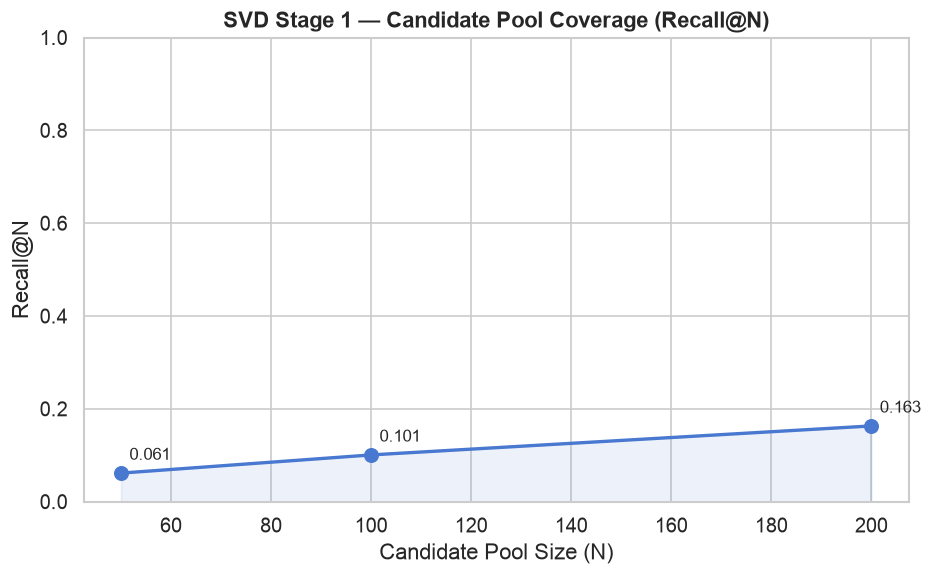

In [45]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(recall_df.index, recall_df['Recall@N'].values, marker='o', linewidth=2,
        color=sns.color_palette('muted')[0], markersize=8)
ax.fill_between(recall_df.index, recall_df['Recall@N'].values, alpha=0.1,
                color=sns.color_palette('muted')[0])
ax.set_title('SVD Stage 1 — Candidate Pool Coverage (Recall@N)', fontsize=13, fontweight='bold')
ax.set_xlabel('Candidate Pool Size (N)')
ax.set_ylabel('Recall@N')
ax.set_ylim(0, 1)
for n, r in zip(recall_df.index, recall_df['Recall@N'].values):
    ax.annotate(f'{r:.3f}', (n, r), textcoords='offset points', xytext=(5, 8), fontsize=10)
plt.tight_layout()
plt.savefig('../reports/intermediate_report/fig_svd_recall.png', bbox_inches='tight')
plt.show()

## Summary

| Metric | Value |
|--------|-------|
| RMSE | 0.8996 |
| MAE | 0.7049 |
| Recall@50 | 0.0614 |
| Recall@100 | 0.1006 |
| Recall@200 | 0.1631 |

→ Continue to `03_stage1_cbf.ipynb`